# 増幅回路(非反転増幅・反転増幅)

信号の電圧を何倍かにする回路です。Mimic では、ゲイン(倍率)をプログラムから変えられる増幅器(**PGA**:Programmable Gain Amplifier)として使います。

この回では、2 倍に増幅する、反転させる、増幅しすぎて頭打ちになる、の 3 つを見ます。最後に、単電源の回路で大事な「信号のグランド(Vref)」の役目を確かめます。

> 準備:[0 章](../00_intro/01_bypass.ipynb)で測定器の使い方を見ておきます。

## 回路

**非反転増幅**(出力は入力と同じ向き):

![非反転増幅](01_pga/circuit_noninverting.svg)

**反転増幅**(出力は入力と逆向き):

![反転増幅](01_pga/circuit_inverting.svg)

5 V だけで動く(単電源の)回路では、図のグランドの記号を 0 V ではなく 2.5 V(**信号のグランド**)につなぎます。Mimic では、この電圧を **Vref** と呼びます(既定で 2.5 V)。

## 原理

オペアンプは、2 つの入力(+ と −)の電圧が等しくなるように出力を動かします(**仮想短絡**)。出力から − 入力へ抵抗で戻しているので、抵抗の比でゲインが決まります(導出は省きます)。

| 回路 | ゲイン $G = V_\mathrm{out} / V_\mathrm{in}$ | 範囲 |
|---|---|---|
| 非反転増幅 | $G = 1 + \dfrac{R_f}{R_g}$ | 1 以上 |
| 反転増幅 | $G = -\dfrac{R_f}{R_\mathrm{in}}$ | 負(向きが逆になる) |

単電源の回路では、電圧は Vref から測ります。

$$V_\mathrm{out} = V_\mathrm{ref} + G\,(V_\mathrm{in} - V_\mathrm{ref})$$

出力は電源(0〜5 V)の少し内側までしか出せないので、$G$ を大きくしすぎると、山と谷が**頭打ち(飽和)**になります。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.pga(G)`($G \ge 1$) | `mimic.setPGA(G)` | 非反転増幅:$R_f / R_g = G - 1$ |
| `lab.mimic.pga(G)`($G < 0$) | `mimic.setPGA(G)` | 反転増幅:$R_f / R_\mathrm{in} = -G$ |
| `lab.mimic.vref(V)` | `mimic.setVref(V)` | 信号のグランドの電圧 |

例:$G = 2$ は $R_f = R_g$ = 10 kΩ の非反転増幅、$G = -1$ は $R_f = R_\mathrm{in}$ = 10 kΩ の反転増幅です。

Mimic では、0 と 1 のあいだのゲイン(小さくする)も同じように設定できます。回路では、抵抗の分圧とボルテージフォロワで作ります。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

## 実験 1:2 倍に増幅する(非反転増幅)

振幅 0.5 V の正弦波を入れて、ゲイン 2 にします。出力の振幅は 1 V になるはずです。

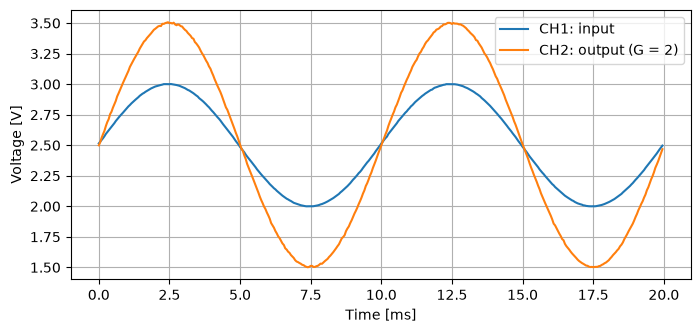

gain  : 1.998  (set 2)
centre: input 2.500 V, output 2.503 V


In [2]:
lab.fg.sine(100, 0.5)  # 100 Hz, 0.5 V peak, around 2.5 V
lab.mimic.pga(2)
t, ch1, ch2 = lab.scope.capture(400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (G = 2)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a1, p1, c1 = fit_sine(t, ch1, 100)
a2, p2, c2 = fit_sine(t, ch2, 100)
print(f"gain  : {a2 / a1:.3f}  (set 2)")
print(f"centre: input {c1:.3f} V, output {c2:.3f} V")

`fit_sine` は、周波数がわかっている正弦波を当てはめて、振幅・位相・中心の電圧を求める関数です(mimiclab に入っています)。出力の中心は入力と同じ 2.5 V のままで、Vref からのずれだけが 2 倍になります。

## 実験 2:反転させる(反転増幅)

ゲイン −1 にします。出力は、入力を 2.5 V を軸にひっくり返した波形になります(位相が 180° ずれる)。

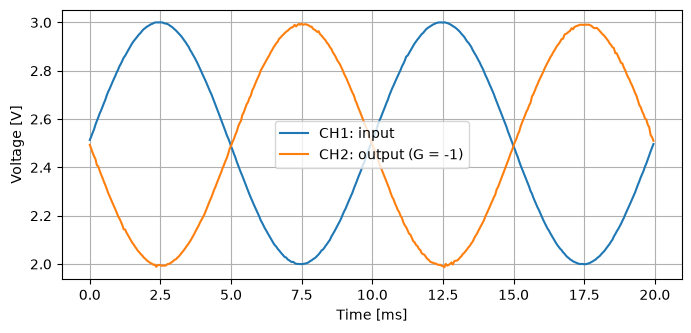

gain : 0.999
phase: 178.2 deg (180 for an inverting amplifier)


In [3]:
lab.mimic.pga(-1)
t, ch1, ch2 = lab.scope.capture(400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (G = -1)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a1, p1, c1 = fit_sine(t, ch1, 100)
a2, p2, c2 = fit_sine(t, ch2, 100)
print(f"gain : {a2 / a1:.3f}")
print(f"phase: {(p2 - p1) % 360:.1f} deg (180 for an inverting amplifier)")

## 実験 3:増幅しすぎる(飽和)

ゲイン 5 にすると、出力の振幅は計算上 2.5 V(0〜5 V)になり、電源の内側に収まりません。山と谷が平らになります。

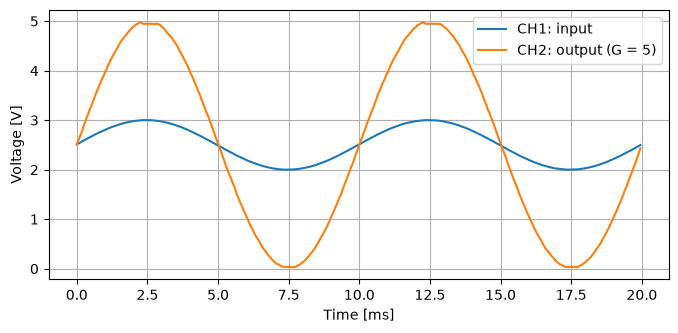

output: 0.029 - 4.977 V


In [4]:
lab.mimic.pga(5)
t, ch1, ch2 = lab.scope.capture(400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (G = 5)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")

## 実験 4:信号のグランド(Vref)をずらす

Mimic の Vref を 2.0 V にして、ゲイン 2 で同じ信号を入れます。入力の中心は 2.5 V のままなので、Mimic から見ると「Vref より 0.5 V 高い直流」が信号に乗っていることになり、それも 2 倍されます。

$$V_\mathrm{out} = 2.0 + 2\,(V_\mathrm{in} - 2.0) \quad\Rightarrow\quad \text{中心は } 2.0 + 2 \times 0.5 = 3.0\ \mathrm{V}$$

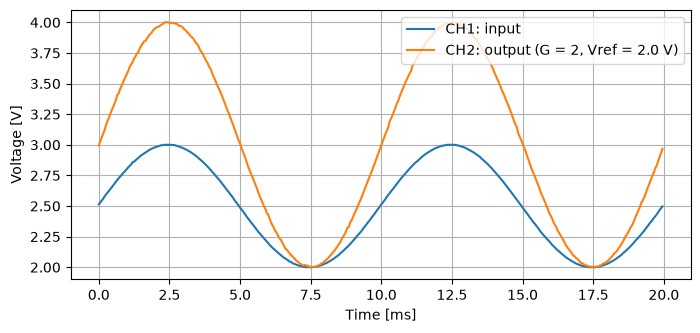

output centre: 3.001 V (expected 3.0)


In [5]:
lab.mimic.pga(2)
lab.mimic.vref(2.0)
t, ch1, ch2 = lab.scope.capture(400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (G = 2, Vref = 2.0 V)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

a2, p2, c2 = fit_sine(t, ch2, 100)
print(f"output centre: {c2:.3f} V (expected 3.0)")
lab.mimic.vref(2.5)  # back to the default

信号のグランドと Vref がずれていると、直流のずれまで増幅されます。講義では、信号発生器のオフセットを Mimic の Vref(2.5 V)に合わせて使います。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. いろいろなゲイン
<details><summary>ヒント</summary>

`GAIN` を 0.5 → −2 → 3 と変えてみましょう。

- 0.5:振幅が半分。回路では、抵抗の分圧とボルテージフォロワで作ります。
- −2:2 倍になって、2.5 V を軸にひっくり返ります(反転増幅)。
- 3:3 倍。振幅 0.5 V なら出力は 1.0〜4.0 V。

</details>

gain 0.499, phase 358 deg


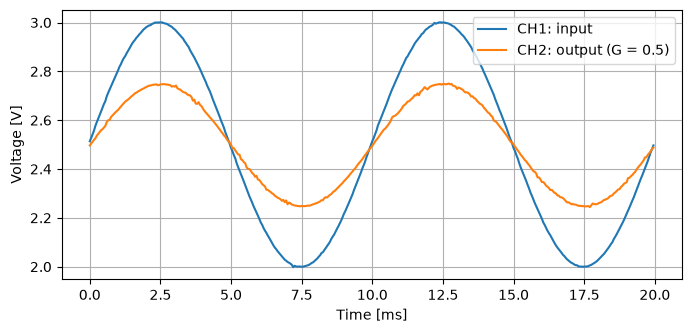

In [6]:
GAIN = 0.5

lab.mimic.vref(2.5)
lab.mimic.pga(GAIN)
lab.fg.sine(100, 0.5)
t, ch1, ch2 = lab.scope.capture(400)
a1, p1, c1 = fit_sine(t, ch1, 100)
a2, p2, c2 = fit_sine(t, ch2, 100)
print(f"gain {a2 / a1:.3f}, phase {(p2 - p1) % 360:.0f} deg")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (G = {GAIN})")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 飽和が始まるゲインを探す

振幅 0.5 V の入力で、ゲインを上げていくと、どこから山が平らになるでしょうか。計算で予想してから確かめます。
<details><summary>ヒント</summary>

`GAIN` を 3 → 4 → 4.8 → 5 → 6 と上げてみましょう。出力の山は 2.5 + 0.5 G [V] です。出力は約 4.9 V までなので、0.5 G = 2.4、つまり G = 4.8 あたりから平らになり始めます。

</details>

output: 1.007 - 4.003 V (without the limit: 1.00 - 4.00 V)


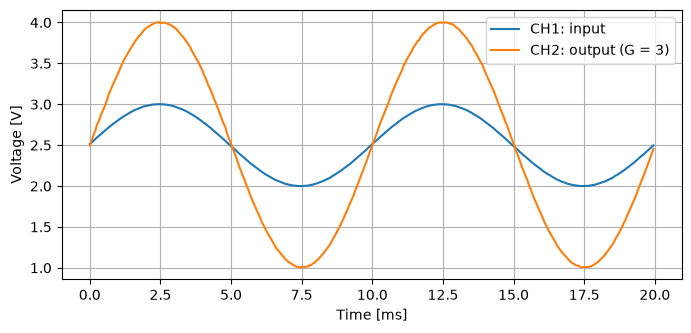

In [7]:
GAIN = 3

lab.mimic.vref(2.5)
lab.mimic.pga(GAIN)
lab.fg.sine(100, 0.5)
t, ch1, ch2 = lab.scope.capture(400)
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V "
      f"(without the limit: {2.5 - 0.5 * abs(GAIN):.2f} - {2.5 + 0.5 * abs(GAIN):.2f} V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (G = {GAIN})")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. Vref をずらす

Vref とゲインを変えて、出力の中心がどう動くかを予想してから確かめます。
<details><summary>ヒント</summary>

中心は $V_\mathrm{ref} + G\,(2.5 - V_\mathrm{ref})$ です。順に試してみましょう。

- `VREF = 2.0`、`GAIN = 1`:中心は 2.5 V のまま(ゲイン 1 では Vref のずれに気づかない)
- `VREF = 2.0`、`GAIN = 3`:中心は 3.5 V
- `VREF = 3.0`、`GAIN = 3`:中心は 1.0 V
- `VREF = 2.5`(元に戻す)

</details>

output centre 2.500 V (expected 2.500 V)


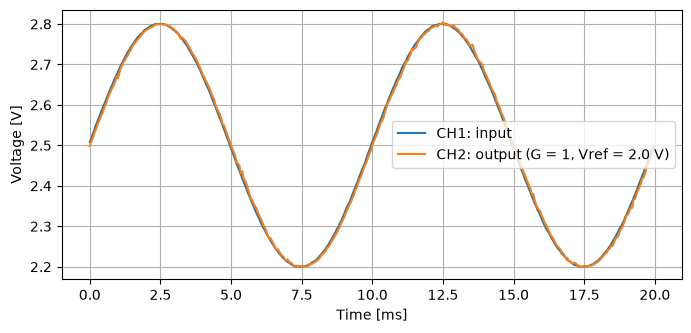

In [8]:
VREF = 2.0
GAIN = 1

lab.mimic.vref(VREF)
lab.mimic.pga(GAIN)
lab.fg.sine(100, 0.3)
t, ch1, ch2 = lab.scope.capture(400)
a2, p2, c2 = fit_sine(t, ch2, 100)
print(f"output centre {c2:.3f} V (expected {VREF + GAIN * (2.5 - VREF):.3f} V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (G = {GAIN}, Vref = {VREF} V)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 非反転増幅は $G = 1 + R_f / R_g$、反転増幅は $G = -R_f / R_\mathrm{in}$。Mimic では `pga(G)` でゲインを直接設定する。
- 増幅するのは信号のグランド(Vref)からのずれ。Vref と信号の中心がずれていると、そのずれも増幅される。
- ゲインを大きくしすぎると、電源の内側で頭打ちになる(飽和)。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.vref(2.5)  # back to the default, if it was changed above
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()